<a href="https://colab.research.google.com/github/DavidBraun777/aerial-fire-vision/blob/AE_BA/second_ae.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from tqdm.auto import tqdm

In [ ]:
print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
splits = pd.read_csv("/content/drive/MyDrive/wildfire_outputs/splits.csv")
IMG = 128

Mounted at /content/drive


In [ ]:
!mkdir -p /content/data
!unzip -q -o "/content/drive/MyDrive/Vision AI Project/Training.zip" -d /content/data
!unzip -q -o "/content/drive/MyDrive/Vision AI Project/Test.zip" -d /content/data
!ls /content/data

Test  Training


In [ ]:
def load_images(paths):
  out = np.empty((len(paths), IMG, IMG,3), dtype=np.uint8)

  for i, p in enumerate(tqdm(paths)):
    out[i] = np.array(Image.open(p).convert("RGB").resize((IMG, IMG)))
  return out

nf_train = splits[(splits.subset == "train") & (splits.label == "No_Fire")].reset_index(drop=True)
nf_val   = splits[(splits.subset == "val")   & (splits.label == "No_Fire")].reset_index(drop=True)
test     = splits[splits.subset == "test"].reset_index(drop=True)

X_train = load_images(nf_train.path)
X_val   = load_images(nf_val.path)
X_test  = load_images(test.path)
y_test  = (test.label == "Fire").astype(int).values   # 1 = fire, 0 = no fire

print("train:", X_train.shape, "| val:", X_val.shape, "| test:", X_test.shape)

  0%|          | 0/11199 [00:00<?, ?it/s]

  0%|          | 0/2871 [00:00<?, ?it/s]

  0%|          | 0/8617 [00:00<?, ?it/s]

train: (11199, 128, 128, 3) | val: (2871, 128, 128, 3) | test: (8617, 128, 128, 3)


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

z = 256

# Encoder: 128x128
enc_in = keras.Input(shape=(IMG, IMG, 3))
x = layers.Conv2D(32,  3, strides=2, padding="same", activation="relu")(enc_in)  # 64x64
x = layers.Conv2D(64,  3, strides=2, padding="same", activation="relu")(x)       # 32x32
x = layers.Conv2D(128, 3, strides=2, padding="same", activation="relu")(x)       # 16x16
x = layers.Conv2D(256, 3, strides=2, padding="same", activation="relu")(x)       # 8x8
x = layers.Flatten()(x)
code = layers.Dense(z, name="code")(x)

# Decoder:128x128 image
x = layers.Dense(8 * 8 * 256, activation="relu")(code)
x = layers.Reshape((8, 8, 256))(x)
x = layers.Conv2DTranspose(128, 3, strides=2, padding="same", activation="relu")(x)  # 16x16
x = layers.Conv2DTranspose(64,  3, strides=2, padding="same", activation="relu")(x)  # 32x32
x = layers.Conv2DTranspose(32,  3, strides=2, padding="same", activation="relu")(x)  # 64x64
x = layers.Conv2DTranspose(16,  3, strides=2, padding="same", activation="relu")(x)  # 128x128
out = layers.Conv2D(3, 3, padding="same", activation="sigmoid")(x)                   # back to 3 colors, 0–1

ae = keras.Model(enc_in, out, name="autoencoder")
ae.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
ae.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ code (Dense)                    │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16384)          │     4,210,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 16, 16, 128)    │       295,040 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 32, 32, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 64, 64, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 128, 128, 16)   │         4,624 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 3)    │           435 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,186,019 (35.04 MB)

 Trainable params: 9,186,019 (35.04 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from pathlib import Path
OUT = Path("/content/drive/MyDrive/wildfire_outputs")

BATCH = 64

def make_ds(X, training):
    ds = tf.data.Dataset.from_tensor_slices(X)
    if training:
        ds = ds.shuffle(len(X), seed=0)
    def prep(x):
        x = tf.cast(x, tf.float32) / 255.0              # 0–255 -> 0–1
        if training:
            x = tf.image.random_flip_left_right(x)      # small augmentation
        return x, x                                     # input = target (copy yourself)
    return ds.map(prep, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(X_train, training=True)
val_ds   = make_ds(X_val,   training=False)

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

In [ ]:
history = ae.fit(train_ds, validation_data=val_ds, epochs=50, callbacks=[early_stop])

Epoch 1/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 10s 58ms/step - loss: 0.0029 - val_loss: 0.0085
Epoch 2/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 10s 54ms/step - loss: 0.0027 - val_loss: 0.0085
Epoch 3/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - loss: 0.0025 - val_loss: 0.0085
Epoch 4/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - loss: 0.0025 - val_loss: 0.0088
Epoch 5/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - loss: 0.0024 - val_loss: 0.0085


In [ ]:
OUT = Path("/content/drive/MyDrive/wildfire_outputs")
ae.save(OUT / "ae_v1_earlystop.keras")

In [ ]:
history = ae.fit(train_ds, validation_data=val_ds, epochs=30)

Epoch 1/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 49ms/step - loss: 0.0028 - val_loss: 0.0085
Epoch 2/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 50ms/step - loss: 0.0026 - val_loss: 0.0086
Epoch 3/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - loss: 0.0024 - val_loss: 0.0083
Epoch 4/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - loss: 0.0024 - val_loss: 0.0088
Epoch 5/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 10s 56ms/step - loss: 0.0023 - val_loss: 0.0082
Epoch 6/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 52ms/step - loss: 0.0022 - val_loss: 0.0084
Epoch 7/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - loss: 0.0022 - val_loss: 0.0084
Epoch 8/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - loss: 0.0021 - val_loss: 0.0085
Epoch 9/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 53ms/step - loss: 0.0020 - val_loss: 0.0082
Epoch 10/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 50ms/step - loss: 0.0020 - val_loss: 0.0081
Epoch 11/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 10s 50ms/step - loss: 0.0020 - val_loss: 0.0085
Epoch 12/30
175/175 ━━━━━━━━━━━━━━━━━━━

In [ ]:
def per_image_error(X, batch=256):
    errs = []
    for i in range(0, len(X), batch):
        xb = X[i:i+batch].astype("float32") / 255.0
        rec = ae.predict(xb, verbose=0)
        errs.append(((rec - xb) ** 2).mean(axis=(1, 2, 3)))
    return np.concatenate(errs)

nf_train["err"] = per_image_error(X_train)
nf_val["err"]   = per_image_error(X_val)

summary = pd.concat([nf_train.assign(subset="train"), nf_val.assign(subset="val")])
print(summary.groupby(["subset", "source"]).err.agg(["mean", "median", "count"]).round(4).to_markdown())

|                                 |   mean |   median |   count |
|:--------------------------------|-------:|---------:|--------:|
| ('train', 'lake_resized_lake_') | 0.0008 |   0.0006 |    9241 |
| ('train', 'resized_')           | 0.0051 |   0.0039 |    1958 |
| ('val', 'lake_resized_lake_')   | 0.0034 |   0.0028 |    2369 |
| ('val', 'resized_')             | 0.0315 |   0.0274 |     502 |


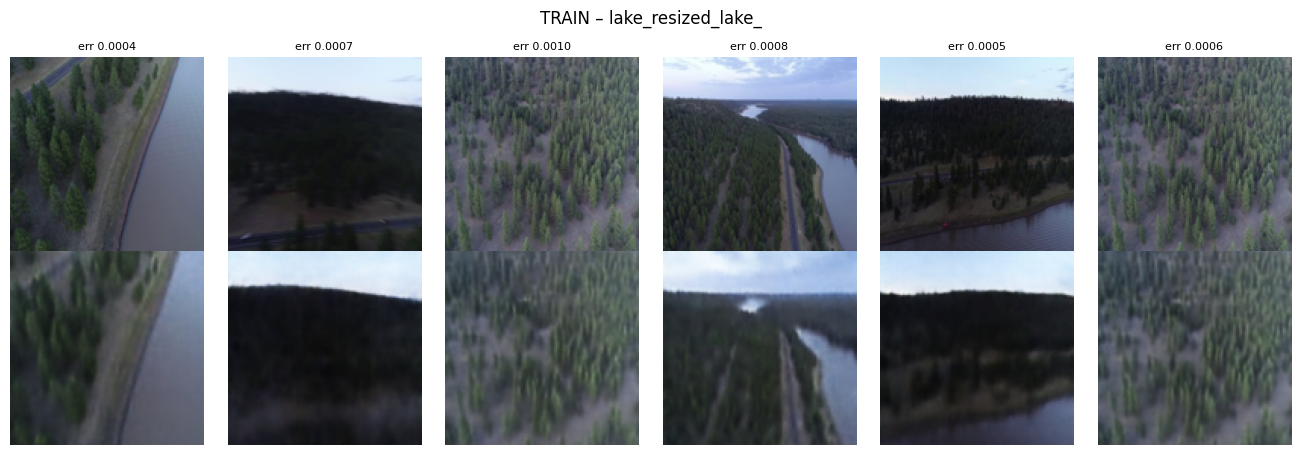

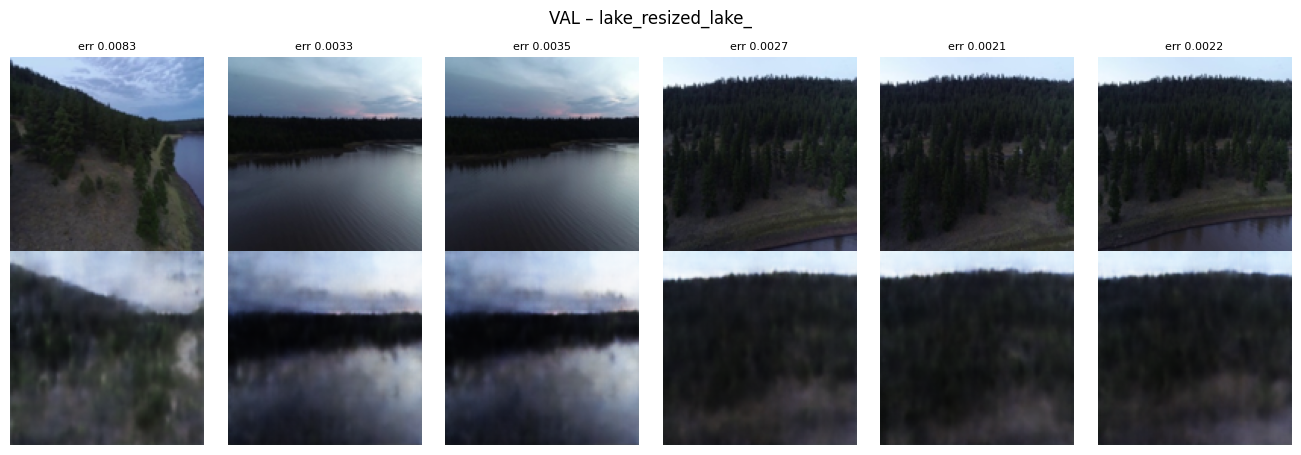

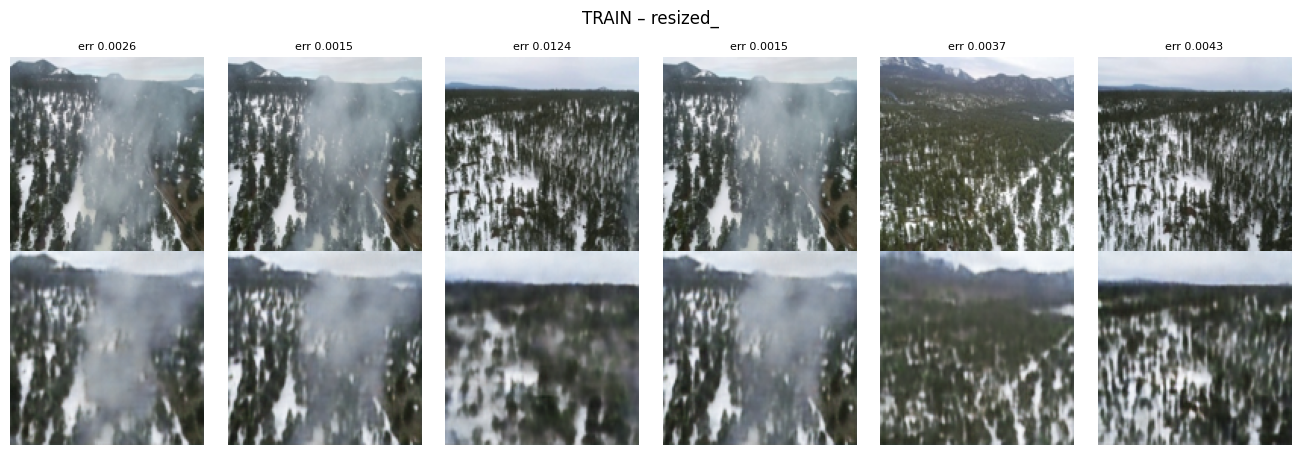

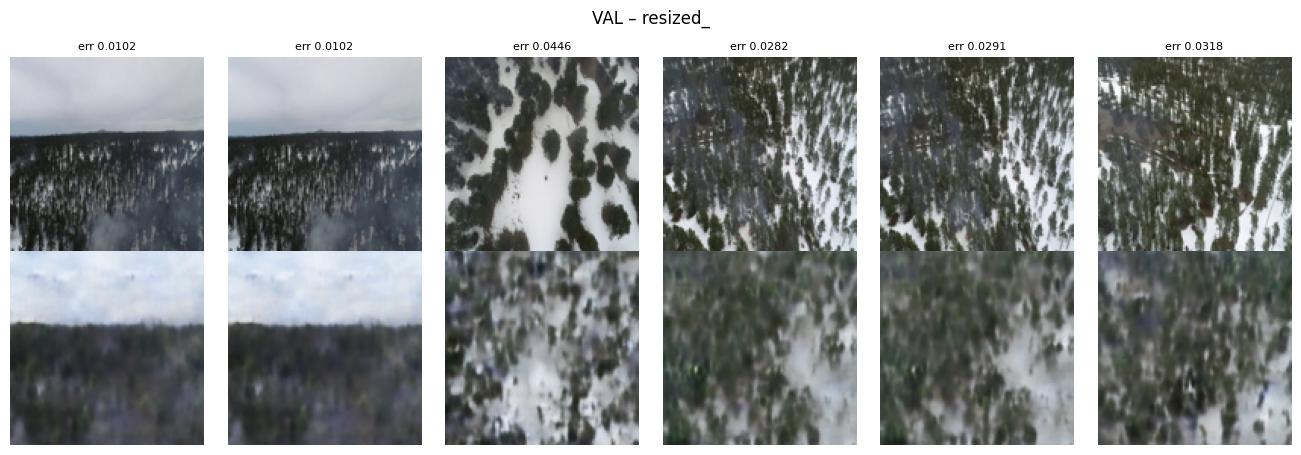

In [ ]:
import matplotlib.pyplot as plt

def show(rows_df, X, title, n=6):
    idx = rows_df.sample(n, random_state=0).index
    xb = X[idx].astype("float32") / 255.0
    rec = ae.predict(xb, verbose=0)
    fig, ax = plt.subplots(2, n, figsize=(2.2*n, 4.6))
    for j in range(n):
        ax[0, j].imshow(xb[j]);  ax[0, j].set_title(f"err {rows_df.loc[idx[j], 'err']:.4f}", fontsize=8)
        ax[1, j].imshow(rec[j])
        ax[0, j].axis("off"); ax[1, j].axis("off")
    ax[0, 0].set_ylabel("original"); ax[1, 0].set_ylabel("rebuild")
    fig.suptitle(title); plt.tight_layout(); plt.show()

for src in ["lake_resized_lake_", "resized_"]:
    show(nf_train[nf_train.source == src], X_train, f"TRAIN – {src}")
    show(nf_val[nf_val.source == src],     X_val,   f"VAL – {src}")